<a href="https://colab.research.google.com/github/hilduAgl/brain-age-eeg/blob/eda/notebooks/eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis

This notebook explores the preprocessed EEG dataset used for brain age prediction.

## Goals

- Load and inspect the EEG data
- Examine the train/validation/test splits
- Explore the age distribution
- Inspect EEG dimensions and channels
- Visualize example EEG recordings
- Compute basic dataset statistics

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Dataset setup

The dataset contains preprocessed EEG recordings together with age and sex metadata. We first inspect the available subjects, metadata, EEG dimensions, and the provided train/validation/test split.

In [5]:
import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "/content/drive/MyDrive/BrainAge/data"
EEG_DIR = os.path.join(DATA_DIR, "pre_processed")
METADATA_PATH = os.path.join(DATA_DIR, "anon_codex_age_sex.csv")

In [6]:
metadata = pd.read_csv(METADATA_PATH)

print("Metadata shape:", metadata.shape)
display(metadata.head())

print(metadata.columns.tolist())
print()
metadata.info()

eeg_files = sorted([
    f for f in os.listdir(EEG_DIR)
    if f.endswith(".pt")
])

print("Number of preprocessed EEG files:", len(eeg_files))
print("First 10 files:")
print(eeg_files[:10])

example_path = os.path.join(EEG_DIR, eeg_files[0])

eeg = torch.load(example_path)

print("File:", eeg_files[0])
print("Type:", type(eeg))
print("Shape:", eeg.shape)
print("Data type:", eeg.dtype)

Metadata shape: (1032, 3)


,Anon. Filename,Quantized Age (years),Quantized Sex
0,2Y32V8.edf,1.487123,Female
1,73K37E.edf,0.375068,Male
2,3FU420.edf,1.841644,Male
3,D9017K.edf,8.061644,Female
4,2QC868.edf,8.880946,Female


['Anon. Filename', 'Quantized Age (years)', 'Quantized Sex']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1032 entries, 0 to 1031
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Anon. Filename         1032 non-null   object 
 1   Quantized Age (years)  1032 non-null   float64
 2   Quantized Sex          1032 non-null   object 
dtypes: float64(1), object(2)
memory usage: 24.3+ KB
Number of preprocessed EEG files: 1034
First 10 files:
['003FL6.pt', '00B64O.pt', '0151RC.pt', '015W5S.pt', '016EF1.pt', '02X87C.pt', '03E99T.pt', '03Q8Y5.pt', '03Z15R.pt', '043I5D.pt']
File: 003FL6.pt
Type: <class 'torch.Tensor'>
Shape: torch.Size([20, 57664])
Data type: torch.float16


## 2. Metadata exploration

We examine the distribution of chronological age and sex in the dataset and check for missing or unusual values.

Number of subjects: 1032
Minimum age: 0.16 years
Maximum age: 16.01 years
Mean age: 4.50 years
Median age: 2.81 years

Sex counts:
Quantized Sex
Male      533
Female    499
Name: count, dtype: int64

Missing values:
Anon. Filename           0
Quantized Age (years)    0
Quantized Sex            0
dtype: int64


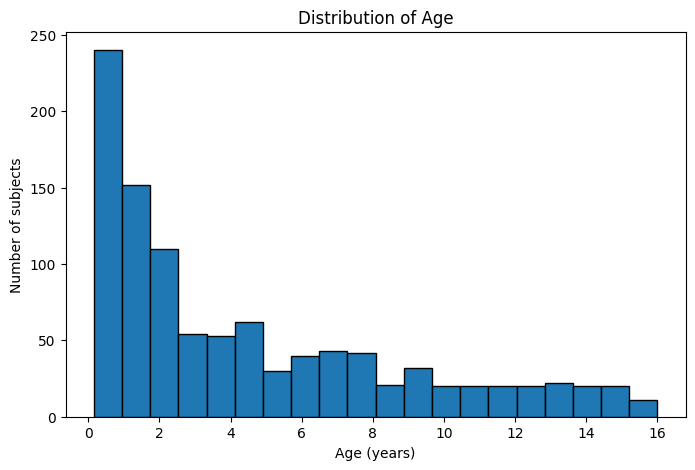

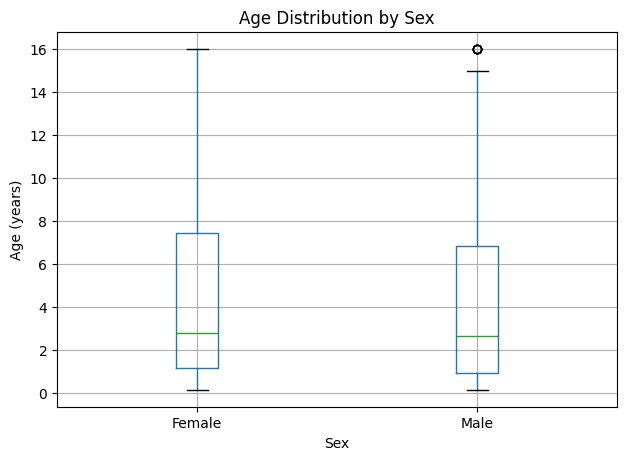

Subjects in metadata: 1032
EEG files: 1034

EEG files without metadata:
['177T6O (1)', '48M4B1 (1)']

Metadata entries without EEG:
[]


In [7]:
AGE_COL = "Quantized Age (years)"
SEX_COL = "Quantized Sex"
FILE_COL = "Anon. Filename"

metadata.describe(include="all")

print(f"Number of subjects: {len(metadata)}")
print(f"Minimum age: {metadata[AGE_COL].min():.2f} years")
print(f"Maximum age: {metadata[AGE_COL].max():.2f} years")
print(f"Mean age: {metadata[AGE_COL].mean():.2f} years")
print(f"Median age: {metadata[AGE_COL].median():.2f} years")

print("\nSex counts:")
print(metadata[SEX_COL].value_counts())

print("\nMissing values:")
print(metadata.isnull().sum())

plt.figure(figsize=(8, 5))
plt.hist(metadata[AGE_COL], bins=20, edgecolor="black")

plt.xlabel("Age (years)")
plt.ylabel("Number of subjects")
plt.title("Distribution of Age")

plt.show()

metadata[SEX_COL].value_counts()

metadata.boxplot(
    column=AGE_COL,
    by=SEX_COL,
    figsize=(7, 5)
)

plt.title("Age Distribution by Sex")
plt.suptitle("")
plt.xlabel("Sex")
plt.ylabel("Age (years)")
plt.show()

metadata_ids = set(
    metadata[FILE_COL]
    .str.replace(".edf", "", regex=False)
)

eeg_ids = set(
    f.replace(".pt", "")
    for f in eeg_files
)

print("Subjects in metadata:", len(metadata_ids))
print("EEG files:", len(eeg_ids))

print("\nEEG files without metadata:")
print(sorted(eeg_ids - metadata_ids))

print("\nMetadata entries without EEG:")
print(sorted(metadata_ids - eeg_ids))

In [8]:
from collections import Counter

shapes = []

for filename in eeg_files:
    eeg_temp = torch.load(os.path.join(EEG_DIR, filename))
    shapes.append(tuple(eeg_temp.shape))

shape_counts = Counter(shapes)

print("Number of unique shapes:", len(shape_counts))

for shape, count in shape_counts.most_common():
    print(shape, ":", count)

Number of unique shapes: 2
(20, 57664) : 1033
(20, 60672) : 1
